# Surrogate Model Convergence
This notebook provides a template for checking and plotting the convergence of surrogate models based on the number of points sampled randomly.
Multiple random samples are taken from each function to check method accuracy relative to number of samples.

In [12]:
%load_ext autoreload
%autoreload 2
#%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import multi_fidelity_functions as mfs
from SurrogateModels import kriging

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Convergence Over Different Dimensions
Test a set of functions from 1-8 dimensions for accuracy in fitting a function

In [13]:
# Set some storage ontainers
error = {}
points = {}

In [14]:
def create_test_points(func: mfs.MultiFidelityTemplate, n=2000):
    # Create a set of samples to create a ground truth
    X_test = func.sample_random(n)
    y_test = func.high_fidelity(X_test)
    return X_test, y_test


def generate_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_low=5,
    sample_high=105,
    step_size=5,
    seeds=5,
    model_error = {},
    points = {}
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_points = list(range(sample_low, sample_high, step_size))
    points[name] = []
    model_error[name] = []
    for seed in range(0, seeds):
        for n in n_points:
            X_train = func.sample_random(n, seed=seed)
            y_train = func.high_fidelity(X_train)
            model = kriging.Kriging(X_train, y_train, nugget=1e-7)
            model_error[name].append(model.model_error(X_test, y_test))
            points[name].append(n)
            print(f"Run {name}: seed {seed}/points {n} complete")

def plot_error_measure(points, error, name, color="blue", marker = "o", label = "Test",ax=None):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.scatter(
        points,
        error,
        color=color,
        label=label,
        marker=marker,
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("RMS Error")
    ax.legend()
    ax.grid()
    ax.set_yscale("log")
    return ax

In [ ]:
# CHECK IF KRIGING MODEL NEEDS OPTIMIZER TUNING ON 1D CASE
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=2000)
generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=5,
    sample_high=150,
    step_size=5,
    seeds=5,
    model_error=error,
    points=points,
)

In [ ]:
ax = plot_error_measure(points[key],error[key],name = key)


In [4]:
# Try running cokriging with error comparisons to the above
import cokriging
import time
import itertools


def generate_cokriging_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_lf=(5, 60),
    sample_hf=(5, 120),
    step_lf=5,
    step_hf=5,
    seeds=5,
    model_error={},
    points_lf={},
    points_hf={},
    training_time={},
    evaluation_time={},
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_lf_range = list(range(*sample_lf, step_lf))
    n_hf_range = list(range(*sample_hf, step_hf))
    points_lf[name] = []
    points_hf[name] = []
    training_time[name] = []
    evaluation_time[name] = []
    model_error[name] = []

    for nh, nl, seed in itertools.product(n_hf_range, n_lf_range, range(seeds)):

        # define training points by randomly sampling functions
        X_train_lf = func.sample_random(nl, seed=seed)
        y_train_lf = func.low_fidelity(X_train_lf)
        X_train_hf = func.sample_random(nh, seed=seed)
        y_train_hf = func.high_fidelity(X_train_hf)

        # Setup timer to gauge model training time
        t0 = time.perf_counter()

        # Train the model
        if nl == 0:
            model = kriging.Kriging(x_mat=X_train_hf, y_vec=y_train_hf, nugget=1e-7)
        else:
            model = cokriging.CoKriging(
                x_lf=X_train_lf,
                y_lf=y_train_lf,
                x_hf=X_train_hf,
                y_hf=y_train_hf,
                nugget=1e-7,
            )
        model_training_time = time.perf_counter() - t0

        # Calculate error using a large number of model samples
        t0 = time.perf_counter()
        error = model.model_error(X_test, y_test)
        model_evaluation_time = time.perf_counter() - t0

        model_error[name].append(error)
        points_lf[name].append(nl)
        points_hf[name].append(nh)
        training_time[name].append(model_training_time)
        evaluation_time[name].append(model_evaluation_time)

        print(
            f"Run {name} :: Seed {seed} :: n_hf {nh} :: n_lf {nl} :: Error {error} :: t_train {model_training_time}"
        )


def plot_cokriging_data(
    points_lf,
    points_hf,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot(projection="3d")
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("Samples HF")
    ax.set_zlabel(label)

    if log_output:
        output = np.log10(output)

    ax.scatter(
        points_lf,
        points_hf,
        output,
        color=color,
        label=label,
    )


def plot_cokriging_data_slice(
    points_lf,
    points_hf,
    output,
    fix_lf=True,
    fix_value=10,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    x_values = []
    y_values = []
    if fix_lf:
        ax.set_xlabel("Samples HF")
        for i, val in enumerate(points_lf):
            if val == fix_value:
                x_values.append(points_hf[i])
                y_values.append(output[i])
    else:
        ax.set_xlabel("Samples_LF")
        for i, val in enumerate(points_hf):
            if val == fix_value:
                x_values.append(points_lf[i])
                y_values.append(output[i])
    ax.set_ylabel(label)

    if log_output:
        y_values = np.log10(y_values)

    print(x_values)
    ax.scatter(
        x_values,
        y_values,
        color=color,
        label=label,
    )
    return ax

In [15]:
# Set storage containers
model_error = {}
points_lf = {}
points_hf = {}
training_time = {}
evaluation_time = {}

In [20]:
key = "1D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=2000)
generate_cokriging_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_lf=(0, 30),
    sample_hf=(10, 30),
    step_lf=5,
    step_hf=5,
    seeds=3,
    model_error = model_error,
    points_lf = points_lf,
    points_hf = points_hf,
    training_time = training_time,
    evaluation_time = evaluation_time,
)

Run 1D :: Seed 0 :: n_hf 10 :: n_lf 0 :: Error 4.337293594160957 :: t_train 0.13275950000388548
Run 1D :: Seed 1 :: n_hf 10 :: n_lf 0 :: Error 0.14334576153027975 :: t_train 0.2713215000112541
Run 1D :: Seed 2 :: n_hf 10 :: n_lf 0 :: Error 0.23894758629601026 :: t_train 0.40065960003994405
Run 1D :: Seed 0 :: n_hf 10 :: n_lf 5 :: Error 2.8023715951662536 :: t_train 0.3230481999926269
Run 1D :: Seed 1 :: n_hf 10 :: n_lf 5 :: Error 7.619226143504723 :: t_train 0.6650662000174634
Run 1D :: Seed 2 :: n_hf 10 :: n_lf 5 :: Error 0.24372548685421613 :: t_train 0.6915698000229895
Run 1D :: Seed 0 :: n_hf 10 :: n_lf 10 :: Error 0.2265239092689901 :: t_train 1.0295794000267051
Run 1D :: Seed 1 :: n_hf 10 :: n_lf 10 :: Error 0.12749519567726672 :: t_train 0.9413501999806613
Run 1D :: Seed 2 :: n_hf 10 :: n_lf 10 :: Error 0.20709856157115653 :: t_train 1.2517856999766082
Run 1D :: Seed 0 :: n_hf 10 :: n_lf 15 :: Error 0.008990745594282541 :: t_train 1.201053500000853
Run 1D :: Seed 1 :: n_hf 10 ::

In [21]:
# Output the results to a csv
import csv
output_file = f"CokrigingResults_{key}_small.csv"
with open(output_file,"w", newline='') as file:
    writer = csv.writer(file)
    for i, val in enumerate(points_lf[key]):
        writer.writerow([val,points_hf[key][i],model_error[key][i],training_time[key][i],evaluation_time[key][i]])

In [ ]:
# Load csv
def load_csv_results_data(file):
    points_lf = []
    points_hf = []
    model_error = []
    training_time = []
    evaluation_time = []

    reader = csv.reader(file)
    for row in reader:
        points_lf.append(row[0])
        points_hf.append(row[1])
        model_error.append(row[2])
        training_time.append(row[3])
        evaluation_time.append(row[4])
    return points_lf, points_hf, model_error, training_time, evaluation_time

In [ ]:
loaded_lf,loaded_hf,loaded_error,loaded_train_time,loaded_evaluation_time = load_csv_results_data('CokrigingResults.csv')

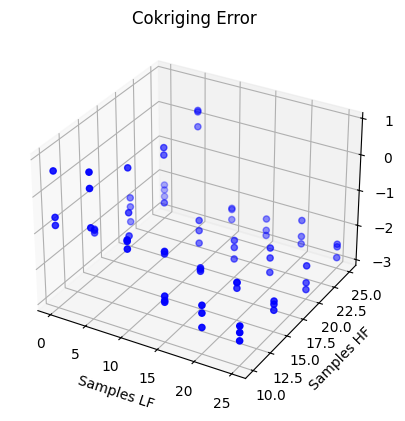

In [22]:
ax = plot_cokriging_data(
    points_lf=points_lf[key], points_hf=points_hf[key], output=model_error[key], label="Log(RMSE)",name="Cokriging Error",log_output=True, color="blue"
)
plt.show()

[10, 10, 10, 15, 15, 15, 20, 20, 20, 25, 25, 25]


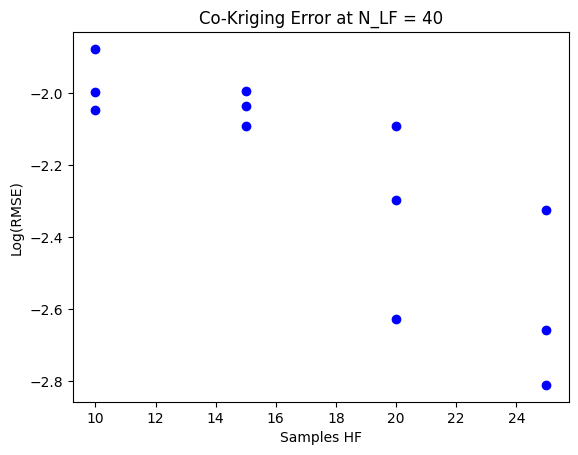

In [ ]:
fix_value = 15
fix_lf = True
plot_cokriging_data_slice(
    points_lf=points_lf[key],
    points_hf=points_hf[key],
    output=model_error[key],
    fix_lf=fix_lf,
    fix_value=fix_value,
    name=f"Co-Kriging Error at N_LF = {fix_value}",
    color="blue",
    label="Log(RMSE)",
    log_output=True,
)
plt.show()

In [ ]:
ax = plot_cokriging_data(
    points_lf=points_lf[key], points_hf=points_hf[key], output=training_time[key], label="RMS Error",name="Cokriging Training Times", 
)

In [ ]:
ax = plot_cokriging_data(
    points_lf=points_lf[key], points_hf=points_hf[key], output=evaluation_time[key], label="RMS Error",name="Cokriging Evaluation Times"
)

In [ ]:
ax = plot_error_measure(points_ck[key],error_ck[key],name = "1D Cokriging Convergence (n_lf=60)")

In [ ]:
X_train_50 = my_function.sample_random(50, seed=1)
y_train_50 = my_function.high_fidelity(X_train_50)
model_50 = kriging.Kriging(X_train_50, y_train_50, nugget=1e-6)
X_train_60 = my_function.sample_random(60, seed=1)
y_train_60 = my_function.high_fidelity(X_train_60)
model_60 = kriging.Kriging(X_train_60, y_train_60, nugget=1e-6)
X_train_70 = my_function.sample_random(70, seed=1)
y_train_70 = my_function.high_fidelity(X_train_70)
model_70 = kriging.Kriging(X_train_70, y_train_70, nugget=1e-6)
X_train_250 = my_function.sample_random(250, seed=1)
y_train_250 = my_function.high_fidelity(X_train_250)
model_250 = kriging.Kriging(X_train_250, y_train_250, nugget=1e-6)


In [ ]:

ax = model_50.plot_model(bounds=my_function.bounds,name="Compare Samples",color="black",label="n=50",n_samples=1000)
ax = model_60.plot_model(bounds=my_function.bounds,name="Compare Samples",color="blue",label="n=60",n_samples=1000,ax=ax)
ax = model_70.plot_model(bounds=my_function.bounds,name="Compare Samples",color="red",label="n=70",n_samples=1000,ax=ax)
ax = model_250.plot_model(bounds=my_function.bounds,name="Compare Samples",color="cyan",label="n=250",n_samples=1000,ax=ax)
ax = my_function.plot_high_fidelity(color="green",ax=ax,n_samples=1000)
ax.scatter(X_train_70,y_train_70,color="red")
ax.scatter(X_train_50,y_train_50,color="black")
ax.scatter(X_train_60,y_train_60,color="blue")
ax.scatter(X_train_250,y_train_250,color="cyan")
ax.legend()
ax.set_title("End Comparison")
# ax.set_xlim([0.97,1.0])
# ax.set_ylim([14,16.5])
plt.show()


In [ ]:
X_train_10 = my_function.sample_random(20, seed=1)
y_train_10 = my_function.high_fidelity(X_train_10)
model_10 = kriging.Kriging(X_train_10, y_train_10, nugget=1e-6)
ax = model_10.plot_model(bounds=my_function.bounds,name="Compare Samples",color="black",label="n=50",n_samples=1000)
ax = my_function.plot_high_fidelity(color="green",ax=ax,n_samples=1000)
plt.show()

In [ ]:
ax = model1.plot_testpoint_error(X_test=X_test, y_test=y_test,label="n = 50")
ax = model2.plot_testpoint_error(X_test=X_test, y_test=y_test,label="n = 60",ax=ax,color="red")
ax = model3.plot_testpoint_error(X_test=X_test, y_test=y_test,label="n = 70",ax=ax,color="green")
#ax.set_yscale("log")
ax.legend()

In [ ]:
ax = model2.plot_model(bounds=my_function.bounds,name="Model Compare",label="n=60",n_samples=2000,color="black")
ax = model1.plot_model(bounds=my_function.bounds,name="Model Compare",label="n=50",n_samples=2000,color="red",ax=ax)
ax = model3.plot_model(bounds=my_function.bounds,name="Model Compare",label="n=70",n_samples=2000,color="green",ax=ax)
ax = my_function.plot_high_fidelity(n_samples=2000,ax=ax)
ax.legend()
ax.set_xlim([0.98,1.0])
ax.set_ylim([15,16.5])

In [ ]:
for key, value in mfs.increasing_dimensions.items():
    my_function = value()
    X_test, y_test = create_test_points(my_function, n=2000)
    generate_model_comparisons(
        key,
        my_function,
        X_test=X_test,
        y_test=y_test,
        sample_low=10,
        sample_high=500,
        step_size=10,
        seeds=5,
        model_error=error,
        points=points,
    )

    

In [ ]:
plot_error_measure(points["1D"],error["1D"],name = "1D",ax=ax,color="red",label="LBFGS")
plot_error_measure(points["2D"],error["2D"],name = "2D")
plot_error_measure(points["4D"],error["4D"],name = "4D")
plot_error_measure(points["6D"],error["6D"],name = "6D")
plot_error_measure(points["8D"],error["8D"],name = "8D")

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105, 5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1e-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["2D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["4D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["6D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n * my_function.dimensions, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n * my_function.dimensions)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

In [ ]:
# Define the function
my_function = mfs.increasing_dimensions["8D"]

# Create a set of samples to create a ground truth
# Here n = 100*dimensions is used
n = 100 * my_function.dimensions
X_test = my_function.sample_uniform(n)
y_test = my_function.high_fidelity(X_test)

In [ ]:
# Generate a Kriging model of the data and test accuracy using a number of random sample points
n_points = list(range(5, 105,5))
points = []
model_error = []
for seed in range(1, 4):
    for n in n_points:
        X_train = my_function.sample_random(n * my_function.dimensions, seed=seed)
        y_train = my_function.high_fidelity(X_train)
        model = kriging.Kriging(X_train, y_train, nugget=1E-7)
        model_error.append(model.model_error(X_test, y_test))
        points.append(n * my_function.dimensions)

In [ ]:
plot_name = "Accuracy Relative to Number of Points"
plt.figure(plot_name)
plt.title("")
plt.scatter(
    points,
    model_error,
    color="blue",
    label="Test Points",
    marker="o",
)
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()